In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)

In [2]:
square = np.array([
    [0, 0],
    [1, 0],
    [1, 1],
    [0, 1],
    [0, 0]
])

F = np.array([
    [0.2, 0.1],
    [0.4, 0.1],
    [0.4, 0.45],
    [0.65, 0.45],
    [0.65, 0.6],
    [0.4, 0.6],
    [0.4, 0.75],
    [0.8, 0.75],
    [0.8, 0.9],
    [0.2, 0.9],
    [0.2, 0.1]
])

In [3]:
square

array([[0, 0],
       [1, 0],
       [1, 1],
       [0, 1],
       [0, 0]])

In [7]:
def plot_transformation(A):
    A = np.array(A, dtype=float)

    square2 = square @ A.T
    F2 = F @ A.T

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    #before transformation
    axes[0].plot(square[:, 0], square[:, 1], color="blue")
    axes[0].fill(F[:, 0], F[:, 1], color="red")

    #after transformation
    axes[1].plot(square2[:, 0], square2[:, 1], color="blue")
    axes[1].fill(F2[:, 0], F2[:, 1], color="red")

    #grid lines
    for t in [0.25, 0.5, 0.75]:
        v = np.array([[t, 0], [t, 1]])
        h = np.array([[0, t], [1, t]])

        axes[0].plot(v[:, 0], v[:, 1], color="gray")
        axes[0].plot(h[:, 0], h[:, 1], color="gray")

        v2 = v @ A.T
        h2 = h @ A.T

        axes[1].plot(v2[:, 0], v2[:, 1], color="gray")
        axes[1].plot(h2[:, 0], h2[:, 1], color="gray")

    axes[0].set_title("before")
    axes[1].set_title("after")

    for ax in axes:
        ax.set_aspect("equal")
        ax.grid(True)

    plt.tight_layout()
    plt.show()

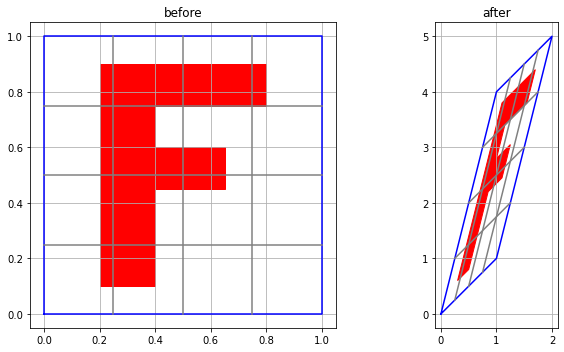

In [12]:
A = np.array([
    [1, 1],
    [1, 4]
])

plot_transformation(A)

Blue is unit square boundaries
Orange is the letter F
Gray is the internal grid of the unit square

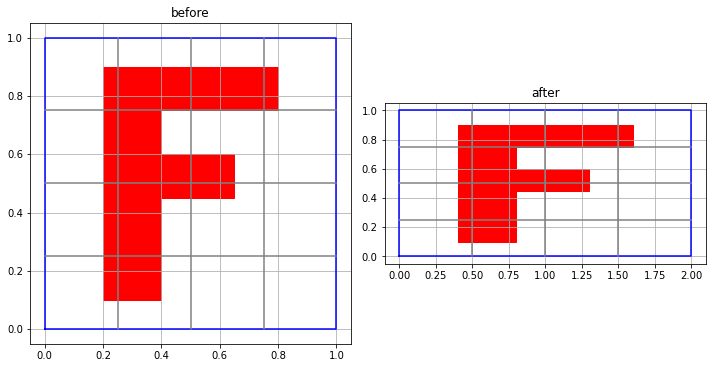

In [13]:
#stretch: T(x, y) = (2x, y)
A1 = np.array([
    [2, 0],
    [0, 1]
])
plot_transformation(A1)

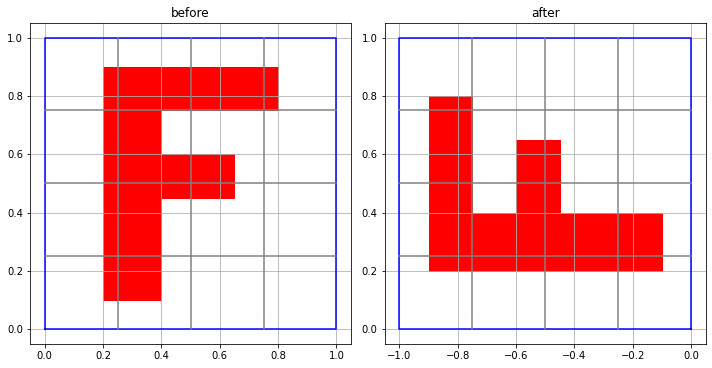

In [14]:
#rotation by 90 degrees: T(x, y) = (-y, x)
A2 = np.array([
    [0, -1],
    [1, 0]
])
plot_transformation(A2)

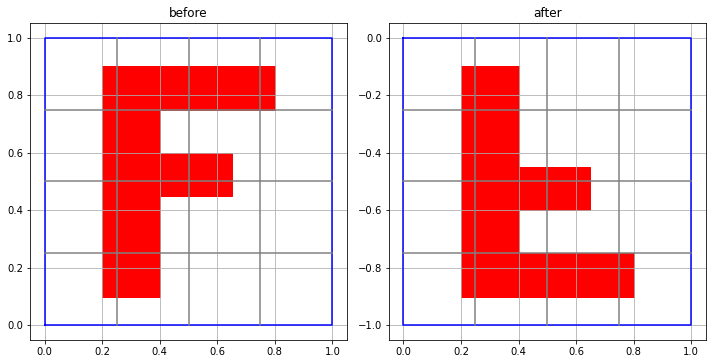

In [15]:
#reflection in the x-axis: T(x, y) = (x, -y)
A3 = np.array([
    [1, 0],
    [0, -1]
])
plot_transformation(A3)

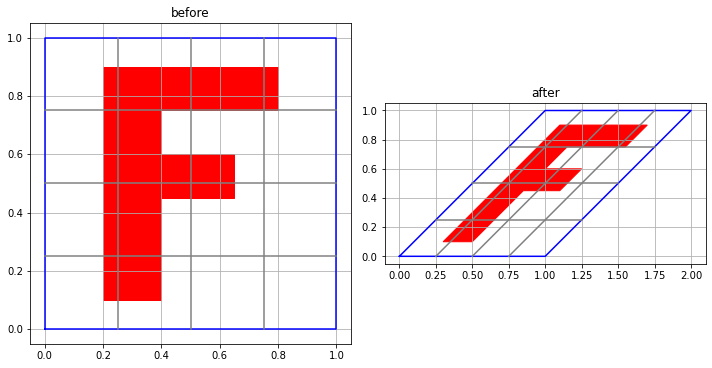

In [16]:
#shear: T(x, y) = (x + y, y)
A4 = np.array([
    [1, 1],
    [0, 1]
])
plot_transformation(A4)

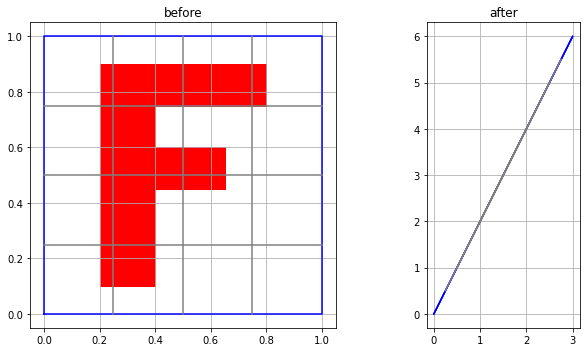

In [17]:
#singular matrix
A5 = np.array([
    [1, 2],
    [2, 4]
])

plot_transformation(A5)

In [18]:
def signed_area(P):
    area = 0
    n = len(P)

    for i in range(n):
        j = (i + 1) % n
        area += P[i, 0] * P[j, 1] - P[j, 0] * P[i, 1]

    return area / 2

In [21]:
square = np.array([
    [0, 0],
    [1, 0],
    [1, 1],
    [0, 1]])

A6 = np.array([
    [3, 1],
    [1, 2]])

matrices = [square,A1, A2, A3, A4, A5, A6]

for A in matrices:
    P = square @ A.T
    area = signed_area(P)
    det = A[0, 0] * A[1, 1] - A[0, 1] * A[1, 0]

    print("matrix:\n", A)
    print("signed area:", area)
    print("det:", det)

    if np.isclose(area, det):
        print("equals")
    else:
        print("not equal")

matrix:
 [[0 0]
 [1 0]
 [1 1]
 [0 1]]
signed area: 0.0
det: 0
equals
matrix:
 [[2 0]
 [0 1]]
signed area: 2.0
det: 2
equals
matrix:
 [[ 0 -1]
 [ 1  0]]
signed area: 1.0
det: 1
equals
matrix:
 [[ 1  0]
 [ 0 -1]]
signed area: -1.0
det: -1
equals
matrix:
 [[1 1]
 [0 1]]
signed area: 1.0
det: 1
equals
matrix:
 [[1 2]
 [2 4]]
signed area: 0.0
det: 0
equals
matrix:
 [[3 1]
 [1 2]]
signed area: 5.0
det: 5
equals
